# Surprise Features

An open causal language model (Qwen2.5-0.5B, open weights, never trained here) scores how predictable every token of a text is. Per-text features from these scores are added to a stacker next to the 03 encoder's logits. Scoring needs a GPU; everything else runs on CPU from `ARTIFACTS_DIR`.

In [1]:
import sys
from pathlib import Path

# Make the repo importable: the local checkout, or a fresh clone on Kaggle/Colab. Then pin versions that must match.
REPO_URL = "https://github.com/BohdanZasymovych/ai-hw3-ai-text-detection.git"
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "setup_env.py").exists()), None)
if REPO is None:
    REPO = Path("/kaggle/working/hw3" if Path("/kaggle").exists() else "/content/hw3")
    if REPO.exists():
        !git -C {REPO} pull -q
    else:
        !git clone -q --depth 1 {REPO_URL} {REPO}
sys.path.insert(0, str(REPO))

import setup_env

setup_env.install_pins()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from utils import (ARTIFACTS_DIR, DATA_DIR, ENV, LABEL_COLORS, LABEL_ORDER, MODEL_COLORS, SURPRISE_MODEL, SEED, cached,
                   compare_f1, compare_groups, ensure_data, ensure_dirs, find_artifact, get_split, load_key,
                   macro_f1, plot_compare, submit_to_kaggle, write_submission)
from utils.surprise import FEATURES, surprise_features, token_surprise
from utils.stacking import fit_predict, oof_predict

ensure_dirs()
ensure_data()
split = get_split()  # fixed train/val split, made and cached on first use
gpu = f"{torch.cuda.device_count()}x {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else "none"
print(f"env={ENV}  gpu={gpu}  data={DATA_DIR}  artifacts={ARTIFACTS_DIR}")

SUBMIT = False  # True: save the test predictions and upload the submission to Kaggle (5 uploads a day)

/home/bohdan/code/ai/hw3-ai-text-detection/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/split.pkl
env=local  gpu=none  data=/home/bohdan/code/ai/hw3-ai-text-detection/data  artifacts=/home/bohdan/code/ai/hw3-ai-text-detection/artifacts


## Data

Load the fixed validation split and the test set, and the 03 encoder's validation and test logits. No training data is needed: the stacker is fitted on validation rows only (out-of-fold).

In [2]:
train_full = pd.read_csv(DATA_DIR / "train.csv")
val = train_full.iloc[split["val"]].reset_index(drop=True)
del train_full
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
label_order = np.array(LABEL_ORDER)

ENC_KEY = load_key("encoder_val_logits")  # settings of the 03 encoder run
assert ENC_KEY is not None, "03 results not found: attach the 03_encoder output or copy its artifacts"
enc = {name: np.load(find_artifact(f"encoder_{name}_logits", "npy")) for name in ["val", "test"]}

pd.DataFrame({"texts": [len(val), len(test)]}, index=["validation", "test"])

,texts
validation,27238
test,25000


## Token Surprise

For every token $t_i$ the language model gives $p_\theta(t_i \mid t_1, \dots, t_{i-1})$. Its surprise is $s_i = -\log p_\theta(t_i \mid t_{<i})$, and the perplexity of a text is $\exp\big(\frac{1}{n}\sum_i s_i\big)$. Text generated by an LLM is predictable to another LLM (low surprise), human text less so, and fusion mixes both. The first 2,048 tokens of each validation and test text are scored; the result is cached.

In [3]:
MAX_TOKENS, CHUNK = 2048, 128
surprise_key = {"model": SURPRISE_MODEL, "max_tokens": MAX_TOKENS, "n_val": len(val), "n_test": len(test), "v": 1}
surprise = {name: cached(f"surprise_{name}", lambda: token_surprise(df["text"], SURPRISE_MODEL, MAX_TOKENS),
                         key={**surprise_key, "part": name})
            for name, df in [("val", val), ("test", test)]}

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/surprise_val.pkl
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/surprise_test.pkl


Surprise along one news text of each class, as the mean of consecutive 128-token chunks.

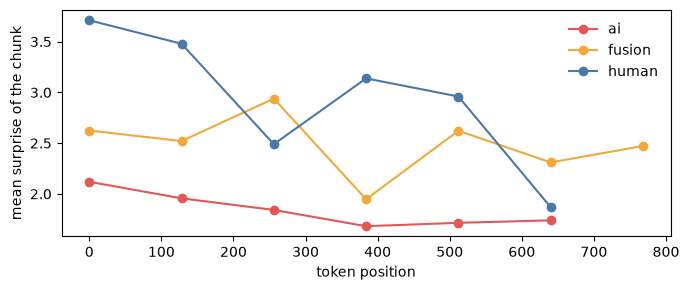

In [4]:
long_enough = np.array([len(s) >= 6 * CHUNK for s in surprise["val"]])
picked = val[long_enough & (val["domain"] == "cnn_news")].groupby("label").sample(1, random_state=SEED)

fig, ax = plt.subplots(figsize=(7, 3))
for i, label in zip(picked.index, picked["label"]):
    s = surprise["val"][i]
    means = [c.mean() for c in np.array_split(s, len(s) // CHUNK)]
    ax.plot(np.arange(len(means)) * CHUNK, means, marker="o", color=LABEL_COLORS[label], label=label)
ax.set_xlabel("token position")
ax.set_ylabel("mean surprise of the chunk")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Features

Five features per text: the mean and the standard deviation of $s_i$, and the spread (standard deviation), minimum and maximum of the chunk means $\bar s_k$ over chunks of 128 tokens. A large spread means some parts of the text are much more predictable than others, which is expected for fusion.

In [5]:
features = {name: surprise_features(s, CHUNK) for name, s in surprise.items()}
features["val"].describe().T[["mean", "std", "min", "50%", "max"]].style.format("{:.2f}")

,mean,std,min,50%,max
surprise mean,2.60,0.70,0.65,2.56,6.55
surprise std,2.58,0.39,1.48,2.59,5.11
chunk spread,0.25,0.17,0.00,0.25,1.85
chunk min,2.26,0.82,0.00,2.17,6.55
chunk max,2.96,0.64,0.88,2.93,6.96


Feature distributions per class. Each feature is shown in standard deviations from the median of its own language and domain, so domain effects are removed (as in the EDA).

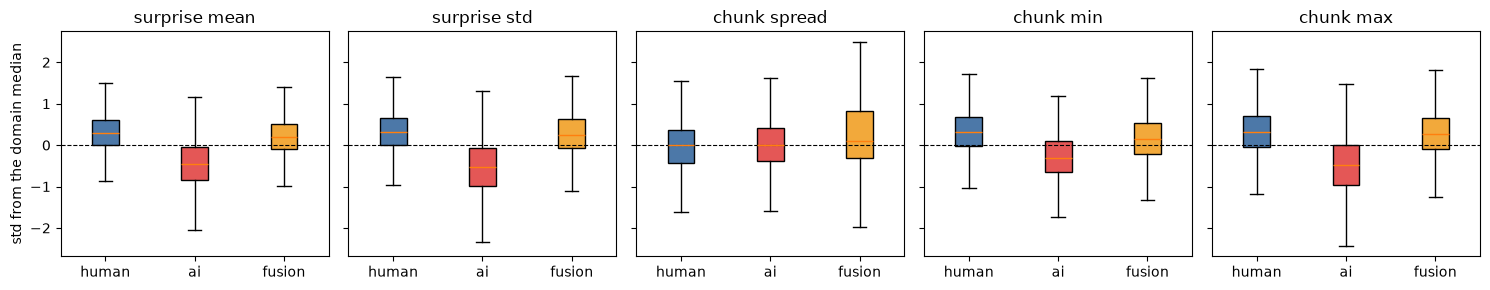

In [6]:
feat = features["val"]
z = (feat - feat.groupby([val["lang"], val["domain"]]).transform("median")) / feat.std()

fig, axes = plt.subplots(1, len(FEATURES), figsize=(3 * len(FEATURES), 3), sharey=True)
for ax, name in zip(axes, FEATURES):
    box = ax.boxplot([z.loc[val["label"] == label, name].dropna() for label in LABEL_ORDER],
                     showfliers=False, patch_artist=True, tick_labels=LABEL_ORDER)
    for patch, label in zip(box["boxes"], LABEL_ORDER):
        patch.set_facecolor(LABEL_COLORS[label])
    ax.axhline(0, color="black", ls="--", lw=0.8)
    ax.set_title(name)
axes[0].set_ylabel("std from the domain median")
plt.tight_layout()
plt.show()

## Stacking

A logistic regression on standardised inputs combines the encoder logits and the features. Every validation row is predicted out-of-fold (5-fold cross-validation inside the validation set), so no row is scored by a stacker that saw it. Columns: `XLM-R base 50k` is the 03 encoder alone (argmax, the reference); `Stack: XLM-R base` uses only its logits (the gain of the stacker itself); `Stack: surprise` uses only the features; `Stack: XLM-R base + surprise` uses both. The gain of surprise is the last column minus `Stack: XLM-R base`.

In [7]:
y = val["label"].to_numpy()
inputs = {
    "Stack: XLM-R base": enc["val"],
    "Stack: surprise": features["val"].to_numpy(),
    "Stack: XLM-R base + surprise": np.hstack([enc["val"], features["val"].to_numpy()]),
}
preds = {"XLM-R base 50k": label_order[enc["val"].argmax(axis=1)], **{name: oof_predict(X, y, SEED) for name, X in inputs.items()}}

compare_f1(y, preds).style.background_gradient(cmap="Blues", axis=None).format("{:.3f}")

,XLM-R base 50k,Stack: XLM-R base,Stack: surprise,Stack: XLM-R base + surprise
human,0.853,0.868,0.305,0.869
ai,0.991,0.992,0.732,0.992
fusion,0.887,0.890,0.476,0.891
macro avg,0.911,0.917,0.504,0.917


Macro-F1 by language and domain.

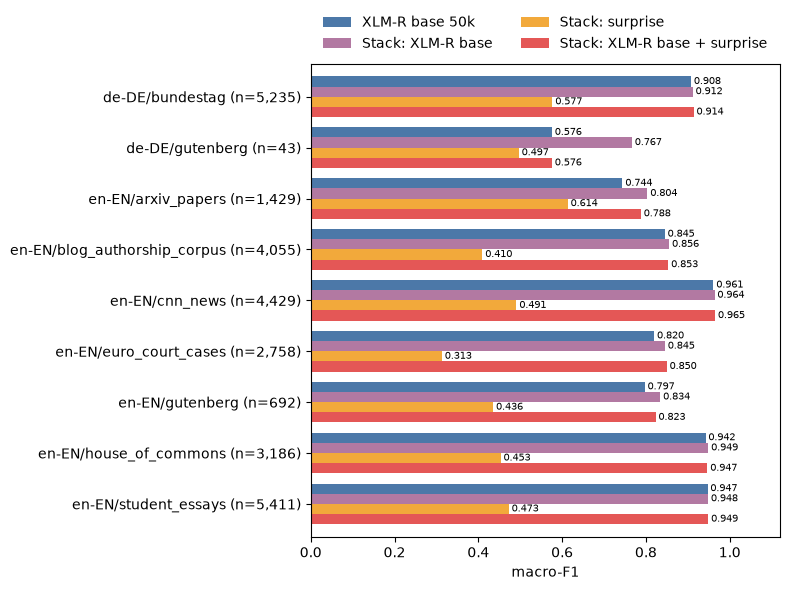

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_compare(compare_groups(val, preds, ["lang", "domain"]), ax, MODEL_COLORS)
plt.tight_layout()
plt.show()

## Submission

Only when `SUBMIT` is True: the stacker on encoder logits + surprise features, fitted on all validation rows, predicts the test set; save a valid submission file and upload it to Kaggle (cached, so a rerun does not spend another daily submission).

In [9]:
test_pred = fit_predict(inputs["Stack: XLM-R base + surprise"], y, np.hstack([enc["test"], features["test"].to_numpy()]))

if SUBMIT:
    # the submission file and upload record keep the old name "perplexity" (saved artifacts)
    path = write_submission(test["id"], test_pred, sample_submission, "perplexity")
    message = f"encoder + surprise stacker ({SURPRISE_MODEL}), val macro-F1 {macro_f1(y, preds['Stack: XLM-R base + surprise']):.3f}"
    cached("perplexity_upload", lambda: submit_to_kaggle(path, message), key={"encoder": ENC_KEY, **surprise_key, "chunk": CHUNK, "seed": SEED}, kind="json")
    display(pd.Series(test_pred).value_counts(normalize=True).reindex(LABEL_ORDER).mul(100).round(1)
            .to_frame("share of test predictions, %").T)
else:
    print("SUBMIT is False: upload skipped")

SUBMIT is False: upload skipped


## Conclusions

- AI text is more predictable to the language model (lower surprise), but human and fusion texts look alike, so the features alone reach only 0.504 macro-F1.
- Added to the encoder logits, they change the stacker by +0.0007, which is noise: the encoder already captures this signal. Surprise is not used in the final pipeline.